In [1]:
import importlib
import os
import sys
from pathlib import Path

import pandas as pd
from IPython.display import display

CODE_DIR = Path.cwd().parent if Path.cwd().name == "train-notebooks" else Path.cwd()
if not ((CODE_DIR / "kev").is_dir() and (CODE_DIR / "data").is_dir() and (CODE_DIR / "training").is_dir()):
    raise RuntimeError(f"Expected code/ root containing kev/, data/, and training/; got {CODE_DIR}")
os.chdir(CODE_DIR)
for _p in (str(CODE_DIR), str(CODE_DIR / "kev")):
    if _p not in sys.path:
        sys.path.insert(0, _p)

import data.persona as _persona_mod
import data.base as _base_mod
import data.marginals as _marginals_mod
import data.issp as _issp_mod
import data.twin2k as _twin2k_mod
import data.twin2k_megastudy as _twin2k_megastudy_mod
import data.grummon2023 as _grummon2023_mod
import data.grummon2025 as _grummon2025_mod
import models.kev_pointer as _kev_pointer_mod
import training.plotter as _plotter_mod
import training.trainer as _trainer_mod
import training.iid_trainer as _iid_trainer_mod
import training.marginal_trainer as _marginal_trainer_mod
import training.chunked_trainer as _chunked_trainer_mod
import training as _training_pkg

for _mod in (
    _persona_mod,
    _base_mod,
    _marginals_mod,
    _issp_mod,
    _twin2k_mod,
    _twin2k_megastudy_mod,
    _grummon2023_mod,
    _grummon2025_mod,
    _kev_pointer_mod,
    _plotter_mod,
    _trainer_mod,
    _iid_trainer_mod,
    _marginal_trainer_mod,
    _chunked_trainer_mod,
    _training_pkg,
):
    importlib.reload(_mod)

from data.base import build_eval_set, build_persona_dataset
from data.grummon2023 import load_grummon2023_df
from data.grummon2025 import ARM_NAMES, PRIMARY_CHOICE_STEMS, load_grummon2025
from data.issp import load_issp_df
from data.marginals import DEFAULT_K_SCHEDULE, build_marginal_lookup
from data.twin2k import load_twin2k_df
from data.twin2k_megastudy import load_twin2k_megastudy_df
from training import ChunkedMarginalTrainer, free_gpu

print(f"Working directory: {Path.cwd()}")

Working directory: /home/dw/github/decision-models-finetuning/code


## 1. Load ISSP, Twin-2K, Twin mega, Grummon 2023 (train + valid) and Grummon 2025 (eval)

In [2]:
INCLUDE_COUNTRY = False
VALID_SEED = 0
N_ISSP_PER_YEAR = 4
N_TWIN_FAMILIES = 40
MEGA_MIN_RESP = 100
N_GRUMMON2023_PER_ARM = 1
MAX_VALID_RESP_PER_QID = 100
SIM_THRESHOLD = 0.95

issp_df = load_issp_df()
twin_df = load_twin2k_df()
mega_df = load_twin2k_megastudy_df()
grummon2023_df = load_grummon2023_df()
all_df = pd.concat([issp_df, twin_df, mega_df, grummon2023_df], ignore_index=True)
q_text_map = all_df.groupby("qid")["question"].first().str.strip().to_dict()

# Share of Twin-2K questions held out (40 / 974); reused for Twin mega
TWIN_VALID_SHARE = N_TWIN_FAMILIES / twin_df["qid"].nunique()

print(
    f"ISSP         : {len(issp_df):>10,} rows | {issp_df['qid'].nunique():>4} questions\n"
    f"Twin-2K      : {len(twin_df):>10,} rows | {twin_df['qid'].nunique():>4} questions\n"
    f"Twin mega    : {len(mega_df):>10,} rows | {mega_df['qid'].nunique():>4} questions\n"
    f"Grummon 2023 : {len(grummon2023_df):>10,} rows | {grummon2023_df['qid'].nunique():>4} questions\n"
    f"Total        : {len(all_df):>10,} rows | {all_df['qid'].nunique():>4} questions\n"
    f"Twin-2K valid share: {TWIN_VALID_SHARE:.4f}"
)

ISSP         :    767,484 rows |  616 questions
Twin-2K      :  1,127,649 rows |  974 questions
Twin mega    :    287,033 rows | 2835 questions
Grummon 2023 :    254,145 rows |  160 questions
Total        :  2,436,311 rows | 4585 questions
Twin-2K valid share: 0.0411


### Valid: ISSP (4 per year)

In [3]:
import random

rng = random.Random(VALID_SEED)

valid_by_group = {}
candidate_queues = {}

for yr, grp in sorted(issp_df.groupby(issp_df["qid"].str.split(":").str[0])):
    qids = sorted(grp["qid"].unique())
    shuffled = rng.sample(qids, len(qids))
    valid_by_group[yr] = shuffled[:N_ISSP_PER_YEAR]
    candidate_queues[yr] = shuffled[N_ISSP_PER_YEAR:]

### Valid: Twin-2K (40 families)

In [4]:
rng = random.Random(VALID_SEED)

twin_by_family = {}
for qid in sorted(twin_df["qid"].unique()):
    fam = qid.split("_")[0]
    twin_by_family.setdefault(fam, []).append(qid)

shuffled_families = rng.sample(sorted(twin_by_family), len(twin_by_family))
twin_pool = [rng.choice(twin_by_family[fam]) for fam in shuffled_families]
valid_by_group["twin2k"] = twin_pool[:N_TWIN_FAMILIES]
candidate_queues["twin2k"] = twin_pool[N_TWIN_FAMILIES:]

### Valid: Twin mega (Twin-2K share per study, n >= 100)

In [5]:
# Twin mega: per study, hold out TWIN_VALID_SHARE of its questions (at least 1),
# drawn only from questions with >= MEGA_MIN_RESP respondents
rng = random.Random(VALID_SEED)

mega_n = mega_df.groupby("qid").size()
mega_study = pd.Series(mega_n.index.str.split(":").str[1].str.rsplit("-QID", n=1).str[0], index=mega_n.index)

mega_rows = []
for study in sorted(mega_study.unique()):
    study_qids = sorted(mega_study.index[mega_study == study])
    eligible = sorted(q for q in study_qids if mega_n[q] >= MEGA_MIN_RESP)
    n_valid = min(max(1, round(TWIN_VALID_SHARE * len(study_qids))), len(eligible))
    shuffled = rng.sample(eligible, len(eligible))
    if n_valid > 0:
        valid_by_group[f"mega:{study}"] = shuffled[:n_valid]
        candidate_queues[f"mega:{study}"] = shuffled[n_valid:]
    mega_rows.append({"study": study, "questions": len(study_qids), f"n>={MEGA_MIN_RESP}": len(eligible), "valid": n_valid})

display(pd.DataFrame(mega_rows))

,study,questions,n>=100,valid
0,accuracy-nudges,26,18,1
1,affective-priming,22,22,1
2,consumer-minimalism,14,14,1
3,context-effects,10,10,1
4,default-eric,4,4,1
5,digital-certification,3,3,1
6,hiring-algorithms,81,81,3
7,idea-evaluation,1200,0,0
8,infotainment,29,29,1
9,junk-fees,179,102,7


In [6]:
mega_rows

[{'study': 'accuracy-nudges', 'questions': 26, 'n>=100': 18, 'valid': 1},
 {'study': 'affective-priming', 'questions': 22, 'n>=100': 22, 'valid': 1},
 {'study': 'consumer-minimalism', 'questions': 14, 'n>=100': 14, 'valid': 1},
 {'study': 'context-effects', 'questions': 10, 'n>=100': 10, 'valid': 1},
 {'study': 'default-eric', 'questions': 4, 'n>=100': 4, 'valid': 1},
 {'study': 'digital-certification', 'questions': 3, 'n>=100': 3, 'valid': 1},
 {'study': 'hiring-algorithms', 'questions': 81, 'n>=100': 81, 'valid': 3},
 {'study': 'idea-evaluation', 'questions': 1200, 'n>=100': 0, 'valid': 0},
 {'study': 'infotainment', 'questions': 29, 'n>=100': 29, 'valid': 1},
 {'study': 'junk-fees', 'questions': 179, 'n>=100': 102, 'valid': 7},
 {'study': 'obedient-twins', 'questions': 18, 'n>=100': 18, 'valid': 1},
 {'study': 'preference-redistribution',
  'questions': 26,
  'n>=100': 26,
  'valid': 1},
 {'study': 'privacy', 'questions': 10, 'n>=100': 10, 'valid': 1},
 {'study': 'promiscuous-donors

### Valid: Grummon 2023 (1 per arm)

In [7]:
# Grummon 2023: N_GRUMMON2023_PER_ARM questions per label arm
rng = random.Random(VALID_SEED)

grummon2023_arm = grummon2023_df["qid"].str.split(":").str[1]
for arm, grp in sorted(grummon2023_df.groupby(grummon2023_arm)):
    qids = sorted(grp["qid"].unique())
    shuffled = rng.sample(qids, len(qids))
    valid_by_group[f"grummon2023:{arm}"] = shuffled[:N_GRUMMON2023_PER_ARM]
    candidate_queues[f"grummon2023:{arm}"] = shuffled[N_GRUMMON2023_PER_ARM:]

### Replace valid questions too similar to train (rapidfuzz)

In [8]:
import numpy as np
from rapidfuzz import fuzz, process

def find_train_matches(valid_qids, q_text_map, threshold=SIM_THRESHOLD):
    valid_set = set(valid_qids)
    train_qids = [q for q in q_text_map if q not in valid_set]
    scores = process.cdist(
        [q_text_map[q] for q in valid_qids],
        [q_text_map[q] for q in train_qids],
        scorer=fuzz.ratio,
        dtype=np.float64,
        workers=-1,
    ) / 100.0
    best = scores.argmax(axis=1)
    return {
        vq: (train_qids[j], float(scores[i, j]))
        for i, (vq, j) in enumerate(zip(valid_qids, best))
        if scores[i, j] >= threshold
    }

round_idx = 0
while True:
    round_idx += 1
    current_valid = [q for grp in sorted(valid_by_group) for q in valid_by_group[grp]]
    matches = find_train_matches(current_valid, q_text_map, threshold=SIM_THRESHOLD)
    if not matches:
        print(f"\nRound {round_idx}: 0 matches >= {SIM_THRESHOLD}. All {len(current_valid)} valid questions passed!")
        break

    print(f"\n=== Round {round_idx}: {len(matches)} valid question(s) matched train (>= {SIM_THRESHOLD}) ===")
    for grp in sorted(valid_by_group):
        kept = []
        for vq in valid_by_group[grp]:
            if vq not in matches:
                kept.append(vq)
                continue
            tq, sim = matches[vq]
            if candidate_queues[grp]:
                replacement = candidate_queues[grp].pop(0)
                kept.append(replacement)
                print(f"[{grp}] {vq} -> replaced with {replacement} (matched {tq}, sim={sim:.3f})")
            else:
                print(f"[{grp}] {vq} -> dropped, no candidates left (matched {tq}, sim={sim:.3f})")
        valid_by_group[grp] = kept

VALID_ISSP_QIDS = [q for grp in sorted(valid_by_group) if grp.isdigit() for q in valid_by_group[grp]]
VALID_TWIN_QIDS = list(valid_by_group["twin2k"])
VALID_MEGA_QIDS = [q for grp in sorted(valid_by_group) if grp.startswith("mega:") for q in valid_by_group[grp]]
VALID_GRUMMON2023_QIDS = [q for grp in sorted(valid_by_group) if grp.startswith("grummon2023:") for q in valid_by_group[grp]]
VALID_QIDS = VALID_ISSP_QIDS + VALID_TWIN_QIDS + VALID_MEGA_QIDS + VALID_GRUMMON2023_QIDS

print(
    f"Valid questions: ISSP={len(VALID_ISSP_QIDS)}, Twin-2K={len(VALID_TWIN_QIDS)}, "
    f"Twin mega={len(VALID_MEGA_QIDS)}, Grummon 2023={len(VALID_GRUMMON2023_QIDS)}, total={len(VALID_QIDS)}"
)


=== Round 1: 33 valid question(s) matched train (>= 0.95) ===
[2016] 2016:v42 -> replaced with 2016:v2 (matched 2016:v41, sim=0.975)
[2016] 2016:v26 -> replaced with 2016:v20 (matched 2016:v24, sim=0.969)
[2019] 2019:v57 -> replaced with 2019:v44 (matched 2019:v58, sim=0.966)
[2020] 2020:v14 -> replaced with 2020:v10 (matched 2024:v61, sim=1.000)
[grummon2023:Calorie] grummon2023:Calorie:snack_choice -> replaced with grummon2023:Calorie:trust (matched grummon2023:Calorie:bev_choice, sim=0.962)
[grummon2023:Green] grummon2023:Green:snack_healthyY -> replaced with grummon2023:Green:control (matched grummon2023:Calorie:snack_healthyY, sim=1.000)
[grummon2023:Warning] grummon2023:Warning:bev_healthyG -> replaced with grummon2023:Warning:react_annoy (matched grummon2023:Calorie:bev_healthyG, sim=1.000)
[mega:affective-priming] twin2k-mega:affective-priming-QID43_2 -> replaced with twin2k-mega:affective-priming-QID39_4 (matched twin2k-mega:affective-priming-QID43_1, sim=0.960)
[mega:hiring-

In [9]:
if len(VALID_QIDS) != len(set(VALID_QIDS)):
    raise ValueError("Duplicate qids in VALID_QIDS")

train_df = all_df[~all_df["qid"].isin(VALID_QIDS)].reset_index(drop=True)
valid_full_df = all_df[all_df["qid"].isin(VALID_QIDS)]
valid_df = pd.concat(
    [
        g.sample(n=min(len(g), MAX_VALID_RESP_PER_QID), random_state=VALID_SEED)
        for _, g in valid_full_df.groupby("qid", sort=True)
    ],
    ignore_index=True,
)

print(
    f"train_df      : {len(train_df):>10,} rows | {train_df['qid'].nunique():>4} questions\n"
    f"valid_df (sub): {len(valid_df):>10,} rows | {valid_df['qid'].nunique():>4} questions (<= {MAX_VALID_RESP_PER_QID} resp/question)"
)

train_df      :  2,283,849 rows | 4472 questions
valid_df (sub):     11,300 rows |  113 questions (<= 100 resp/question)


In [10]:
valid_df.columns
valid_df.groupby(['qid'])['CASEID'].nunique().value_counts()

CASEID
100    113
Name: count, dtype: int64

### build datasets

In [11]:
train_df.columns
train_df.head(2)

,CASEID,c_alphan,SEX,AGE,EDULEVEL,RELIGGRP,ATTEND,PARTY_LR,VOTE_LE,URBRURAL,...,arm,HISPANIC,CHILDREN,DIETQUAL,NFPUSE,MEDHELP,VENDING_BEV,VENDING_SNACK,BMI,option_descriptions
0,2015008400000003,United States,Male,65+,College graduate/some postgrad,Catholic,Once a week,Conservative,Yes,The suburbs or outskirts of a big city,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2015008400000005,United States,Female,50-64,College graduate/some postgrad,Atheist,Never,Liberal,Yes,The suburbs or outskirts of a big city,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
train_records = build_persona_dataset(
    train_df, attr_sets=None, include_country=INCLUDE_COUNTRY, desc="train_records_issp_twin_mega_g23"
)
marginal_lookup = build_marginal_lookup(train_df, include_country=INCLUDE_COUNTRY)

valid_grouped = build_eval_set(
    valid_df,
    attr_sets=None, include_country=INCLUDE_COUNTRY, grouped=True, name="valid_issp_twin_mega_g23", valid=True,
)
# grummon2025_grouped = load_grummon2025(attr_sets=None, include_country=INCLUDE_COUNTRY, grouped=True, valid=False)
GRUMMON2025_QIDS = [f"grummon2025:{arm}:{v}" for arm in ARM_NAMES for v in PRIMARY_CHOICE_STEMS]
grummon2025_grouped = load_grummon2025(attr_sets=None, include_country=INCLUDE_COUNTRY, grouped=True, valid=False, qids=GRUMMON2025_QIDS)

eval_records = [valid_grouped, grummon2025_grouped]

print(
    f"Train records : {len(train_records):,} ({train_df['qid'].nunique():,} questions | "
    f"{marginal_lookup.num_unique_personas:,} unique personas, {len(marginal_lookup.trait_masks)} trait-value masks)\n"
    f"Eval sets     : valid={len(valid_grouped['records']):,} ({len(valid_grouped['packed_views']):,} states), "
    f"grummon2025={len(grummon2025_grouped['records']):,} ({len(grummon2025_grouped['packed_views']):,} states)"
)

Loaded 2,283,849 records from train_records_issp_twin_mega_g23_minNone_35d512af.pkl
Loaded 11,300 records from valid_issp_twin_mega_g23_records_minNone_3f72967b.pkl
Train records : 2,283,849 (4,472 questions | 24,151 unique personas, 224 trait-value masks)
Eval sets     : valid=11,300 (5,146 states), grummon2025=33,798 (4,727 states)


In [13]:
train_rec_qids = set(train_df["qid"].unique())
valid_rec_qids = {r["qid"] for r in valid_grouped["records"]}
grummon2025_rec_qids = {r["qid"] for r in grummon2025_grouped["records"]}
train_rec_texts = set(train_df["question"].str.strip().unique())
valid_rec_texts = {r["question"].strip() for r in valid_grouped["records"]}
grummon2025_rec_texts = {r["question"].strip() for r in grummon2025_grouped["records"]}

assert train_rec_qids.isdisjoint(valid_rec_qids), f"Train/Valid QID overlap: {train_rec_qids & valid_rec_qids}"
assert train_rec_qids.isdisjoint(grummon2025_rec_qids), f"Train/Grummon 2025 QID overlap: {train_rec_qids & grummon2025_rec_qids}"
assert train_rec_texts.isdisjoint(valid_rec_texts), "Exact question text overlap between train and valid!"
assert train_rec_texts.isdisjoint(grummon2025_rec_texts), "Exact question text overlap between train and grummon2025!"
assert valid_rec_texts.isdisjoint(grummon2025_rec_texts), "Exact question text overlap between valid and grummon2025!"

print(
    f"QID counts       : train={len(train_rec_qids):,}, valid={len(valid_rec_qids):,}, grummon2025={len(grummon2025_rec_qids):,}\n"
    f"Question overlaps: train∩valid={len(train_rec_texts & valid_rec_texts)}, "
    f"train∩grummon2025={len(train_rec_texts & grummon2025_rec_texts)}, "
    f"valid∩grummon2025={len(valid_rec_texts & grummon2025_rec_texts)}"
)

QID counts       : train=4,472, valid=113, grummon2025=36
Question overlaps: train∩valid=0, train∩grummon2025=0, valid∩grummon2025=0


### See what happens in the new chunked trainer data processing stage

In [14]:
import random
from collections import Counter

from data.base import _record_chars
from data.marginals import build_marginal_epoch_groups
from training.chunked_trainer import (
    build_logical_marginal_groups,
    sample_persona_state,
    split_logical_group_into_microchunks,
)

pd.set_option("display.max_colwidth", 300)

SEED = 0
TARGET_N = 90                                   # track a persona with about this many training questions
V1_MAX_Q, V1_MAX_CHARS, V1_PER_STEP = 32, 20_000, 12
V2_QPG, V2_PER_STEP = 80, 12
V2_MICRO_Q, V2_MICRO_CHARS = 32, 20_000


def source(qid):
    head = qid.split(":")[0]
    return "issp" if head.isdigit() else head


def persona_key(r):
    return tuple(sorted(r["personas"].items()))


counts = Counter(persona_key(r) for r in train_records)
track_key = min(counts, key=lambda k: abs(counts[k] - TARGET_N))
tracked_records = [dict(r, track=True) if persona_key(r) == track_key else r for r in train_records]
mine = [r for r in tracked_records if "track" in r]

print(f"Tracked persona ({len(mine)} questions):")
for col, val in track_key:
    print(f"  {col} = {val}")
display(pd.DataFrame({
    "qid": [r["qid"] for r in mine],
    "source": [source(r["qid"]) for r in mine],
    "chars": [_record_chars(r) for r in mine],
}).sort_values("chars").reset_index(drop=True))

Tracked persona (90 questions):
  AGE = 50-64
  ATTEND = Never
  EDULEVEL = College graduate/some postgrad
  MAINSTAT = In paid work
  MARITAL = Married
  PARTY_LR = Liberal
  RELIGGRP = Atheist
  SEX = Male
  URBRURAL = The suburbs or outskirts of a big city
  US_ETHN1 = England and Wales
  US_INC = $100,000 or more
  US_PRTY = Democrat
  US_REG = West
  VOTE_LE = Yes


,qid,source,chars
0,2022:v31,issp,248
1,2016:v6,issp,272
2,2016:v58,issp,285
3,2016:v59,issp,294
4,2016:v54,issp,300
...,...,...,...
85,2022:v53,issp,674
86,2022:v51,issp,715
87,2022:v54,issp,786
88,2016:v40,issp,838


v1

In [15]:
v1_groups = build_marginal_epoch_groups(
    tracked_records, marginal_lookup,
    max_questions=V1_MAX_Q, max_chars=V1_MAX_CHARS,
    rng=random.Random(f"{SEED}:epoch:0"), k_schedule=DEFAULT_K_SCHEDULE,
)

step_rng = random.Random(SEED)                  # trainer.rng: one persona-order shuffle per group, in epoch order
v1_rows = []
for pos, g in enumerate(v1_groups):
    state = sample_persona_state(g[0]["personas"], rng=step_rng)
    if "track" in g[0]:
        chars = [_record_chars(r) for r in g]
        v1_rows.append({
            "epoch_pos": pos,
            "step": pos // V1_PER_STEP + 1,
            "questions": len(g),
            "sources": dict(Counter(source(r["qid"]) for r in g)),
            "chars_min_max": (min(chars), max(chars)),
            "padded_chars": len(g) * max(chars),
            "forward_passes": 1,
            "k": len(g[0]["personas"]),
            "subpersona": g[0]["attribute"],
            "state_shown": state.replace("\n", " | "),
            "qids": [r["qid"] for r in g],
        })

v1_df = pd.DataFrame(v1_rows)
n_v1_groups = len(v1_groups)
del v1_groups
print(f"v1 epoch: {n_v1_groups:,} groups -> {-(-n_v1_groups // V1_PER_STEP):,} steps")
display(v1_df)

v1 epoch: 95,379 groups -> 7,949 steps


,epoch_pos,step,questions,sources,chars_min_max,padded_chars,forward_passes,k,subpersona,state_shown,qids
0,104,9,32,{'issp': 32},"(248, 378)",12096,1,14,SEX+AGE+EDULEVEL+RELIGGRP+ATTEND+PARTY_LR+VOTE_LE+URBRURAL+MARITAL+MAINSTAT+US_PRTY+US_INC+US_REG+US_ETHN1,"Age: 50-64 | Political party: Democrat | Voted in the last general election: Yes | Region: West | Religion: Atheist | Ancestry: England and Wales | Marital status: Married | Income: $100,000 or more | Main activity: In paid work | Education: College graduate/some postgrad | Political ideology: L...","[2022:v31, 2016:v6, 2016:v58, 2016:v59, 2016:v54, 2016:v56, 2016:v1, 2016:v22, 2022:v13, 2016:v46, 2022:v46, 2016:v31, 2016:v21, 2016:v47, 2022:v61, 2016:v50, 2022:v11, 2016:v25, 2022:v49, 2016:v24, 2022:v48, 2016:v29, 2016:v26, 2016:v55, 2016:v27, 2022:v39, 2022:v44, 2016:v49, 2022:v42, 2022:v1..."
1,15468,1290,24,{'issp': 24},"(435, 786)",18864,1,14,SEX+AGE+EDULEVEL+RELIGGRP+ATTEND+PARTY_LR+VOTE_LE+URBRURAL+MARITAL+MAINSTAT+US_PRTY+US_INC+US_REG+US_ETHN1,Political ideology: Liberal | Attendance of religious services: Never | Education: College graduate/some postgrad | Voted in the last general election: Yes | Age: 50-64 | Ancestry: England and Wales | Main activity: In paid work | Religion: Atheist | Region: West | Marital status: Married | Sex:...,"[2016:v10, 2016:v15, 2016:v5, 2016:v4, 2016:v43, 2016:v33, 2016:v32, 2022:v1, 2022:v38, 2016:v34, 2016:v38, 2016:v39, 2022:v8, 2022:v25, 2022:v24, 2022:v58, 2022:v7, 2022:v50, 2022:v59, 2022:v57, 2016:v42, 2022:v53, 2022:v51, 2022:v54]"
2,24534,2045,2,{'issp': 2},"(838, 1073)",2146,1,3,RELIGGRP+US_INC+US_ETHN1,"Ancestry: England and Wales | Religion: Atheist | Income: $100,000 or more","[2016:v40, 2016:v35]"
3,70612,5885,32,{'issp': 32},"(378, 434)",13888,1,3,EDULEVEL+PARTY_LR+URBRURAL,Political ideology: Liberal | Education: College graduate/some postgrad | Place of living: The suburbs or outskirts of a big city,"[2022:v41, 2016:v48, 2016:v60, 2016:v3, 2022:v33, 2016:v7, 2022:v2, 2022:v3, 2022:v16, 2022:v15, 2022:v56, 2016:v14, 2022:v4, 2016:v9, 2016:v16, 2022:v18, 2022:v17, 2022:v6, 2016:v12, 2016:v13, 2016:v18, 2016:v11, 2016:v45, 2022:v60, 2016:v20, 2016:v37, 2016:v8, 2016:v19, 2016:v17, 2016:v51, 201..."


v2

In [16]:
v2_groups = build_logical_marginal_groups(
    tracked_records, marginal_lookup,
    questions_per_group=V2_QPG,
    rng=random.Random(f"{SEED}:epoch:0"), k_schedule=DEFAULT_K_SCHEDULE,
)

step_rng = random.Random(SEED)                  # trainer.rng: one persona-order shuffle per logical group
v2_rows, v2_chunk_rows = [], []
for pos, g in enumerate(v2_groups):
    state = sample_persona_state(g[0]["personas"], rng=step_rng)
    if "track" in g[0]:
        chunks = split_logical_group_into_microchunks(
            g, micro_max_questions=V2_MICRO_Q, micro_max_chars=V2_MICRO_CHARS
        )
        v2_rows.append({
            "epoch_pos": pos,
            "step": pos // V2_PER_STEP + 1,
            "questions": len(g),
            "sources": dict(Counter(source(r["qid"]) for r in g)),
            "forward_passes": len(chunks),
            "k": len(g[0]["personas"]),
            "subpersona": g[0]["attribute"],
            "state_shown": state.replace("\n", " | "),
            "qids_in_group_order": [r["qid"] for r in g],
        })
        for j, c in enumerate(chunks):
            chars = [_record_chars(r) for r in c]
            v2_chunk_rows.append({
                "step": pos // V2_PER_STEP + 1,
                "logical_group_pos": pos,
                "chunk": j + 1,
                "questions": len(c),
                "sources": dict(Counter(source(r["qid"]) for r in c)),
                "chars_min_max": (min(chars), max(chars)),
                "padded_chars": len(c) * max(chars),
                "qids": [r["qid"] for r in c],
            })

v2_df = pd.DataFrame(v2_rows)
v2_chunk_df = pd.DataFrame(v2_chunk_rows)
n_v2_groups = len(v2_groups)
del v2_groups
print(f"v2 epoch: {n_v2_groups:,} logical groups -> {-(-n_v2_groups // V2_PER_STEP):,} steps")
display(v2_df)
display(v2_chunk_df)

v2 epoch: 39,723 logical groups -> 3,311 steps


,epoch_pos,step,questions,sources,forward_passes,k,subpersona,state_shown,qids_in_group_order
0,17976,1499,45,{'issp': 45},2,14,SEX+AGE+EDULEVEL+RELIGGRP+ATTEND+PARTY_LR+VOTE_LE+URBRURAL+MARITAL+MAINSTAT+US_PRTY+US_INC+US_REG+US_ETHN1,Region: West | Political party: Democrat | Age: 50-64 | Marital status: Married | Voted in the last general election: Yes | Place of living: The suburbs or outskirts of a big city | Ancestry: England and Wales | Political ideology: Liberal | Religion: Atheist | Main activity: In paid work | Sex:...,"[2016:v60, 2016:v54, 2022:v43, 2022:v60, 2022:v8, 2016:v18, 2016:v45, 2022:v17, 2022:v61, 2016:v40, 2022:v56, 2016:v1, 2022:v59, 2022:v48, 2022:v3, 2016:v17, 2016:v38, 2022:v31, 2022:v57, 2016:v51, 2016:v42, 2022:v11, 2022:v16, 2016:v43, 2016:v35, 2022:v15, 2016:v32, 2016:v10, 2022:v44, 2022:v6,..."
1,22743,1896,45,{'issp': 45},2,14,SEX+AGE+EDULEVEL+RELIGGRP+ATTEND+PARTY_LR+VOTE_LE+URBRURAL+MARITAL+MAINSTAT+US_PRTY+US_INC+US_REG+US_ETHN1,"Income: $100,000 or more | Region: West | Sex: Male | Ancestry: England and Wales | Religion: Atheist | Voted in the last general election: Yes | Age: 50-64 | Attendance of religious services: Never | Place of living: The suburbs or outskirts of a big city | Marital status: Married | Education: ...","[2016:v34, 2016:v49, 2016:v58, 2016:v37, 2016:v12, 2016:v33, 2022:v24, 2016:v11, 2016:v30, 2022:v46, 2016:v48, 2022:v50, 2016:v56, 2016:v4, 2022:v1, 2022:v33, 2022:v49, 2022:v7, 2016:v8, 2016:v59, 2016:v50, 2016:v52, 2022:v38, 2016:v53, 2016:v5, 2022:v51, 2016:v19, 2016:v7, 2016:v29, 2016:v55, 2..."


,step,logical_group_pos,chunk,questions,sources,chars_min_max,padded_chars,qids
0,1499,17976,1,32,{'issp': 32},"(248, 433)",13856,"[2022:v31, 2016:v54, 2016:v1, 2016:v22, 2016:v31, 2022:v61, 2022:v11, 2016:v25, 2022:v48, 2016:v26, 2016:v27, 2022:v44, 2022:v14, 2022:v43, 2016:v60, 2016:v3, 2022:v3, 2022:v16, 2022:v15, 2022:v56, 2016:v14, 2022:v4, 2016:v9, 2016:v16, 2022:v18, 2022:v17, 2022:v6, 2016:v18, 2016:v45, 2022:v60, 2..."
1,1499,17976,2,13,{'issp': 13},"(435, 1073)",13949,"[2016:v10, 2016:v43, 2016:v32, 2016:v38, 2016:v39, 2022:v8, 2022:v59, 2022:v57, 2016:v42, 2022:v53, 2022:v54, 2016:v40, 2016:v35]"
2,1896,22743,1,32,{'issp': 32},"(272, 434)",13888,"[2016:v6, 2016:v58, 2016:v59, 2016:v56, 2022:v13, 2016:v46, 2022:v46, 2016:v21, 2016:v47, 2016:v50, 2022:v49, 2016:v24, 2016:v29, 2016:v55, 2022:v39, 2016:v49, 2022:v42, 2016:v30, 2022:v41, 2016:v48, 2022:v33, 2016:v7, 2022:v2, 2016:v12, 2016:v13, 2016:v11, 2016:v20, 2016:v37, 2016:v8, 2016:v19,..."
3,1896,22743,2,13,{'issp': 13},"(436, 715)",9295,"[2016:v15, 2016:v5, 2016:v4, 2016:v33, 2022:v1, 2022:v38, 2016:v34, 2022:v25, 2022:v24, 2022:v58, 2022:v7, 2022:v50, 2022:v51]"


side by side

In [17]:
display(pd.DataFrame({
    "v1": {
        "groups": len(v1_df),
        "steps it appears in": sorted(v1_df["step"]),
        "subpersona draws": len(v1_df),
        "forward passes": int(v1_df["forward_passes"].sum()),
        "mean sources per group": round(v1_df["sources"].map(len).mean(), 2),
    },
    "v2": {
        "groups": len(v2_df),
        "steps it appears in": sorted(v2_df["step"]),
        "subpersona draws": len(v2_df),
        "forward passes": int(v2_df["forward_passes"].sum()),
        "mean sources per group": round(v2_df["sources"].map(len).mean(), 2),
    },
}))

,v1,v2
groups,4,2
steps it appears in,"[9, 1290, 2045, 5885]","[1499, 1896]"
subpersona draws,4,2
forward passes,4,4
mean sources per group,1.0,1.0


In [18]:
v2_groups = build_logical_marginal_groups(
    train_records, marginal_lookup,
    questions_per_group=V2_QPG,
    rng=random.Random(f"{SEED}:epoch:0"), k_schedule=DEFAULT_K_SCHEDULE,
)
k_counts = Counter(min(len(g[0]["personas"]), 6) for g in v2_groups)   # k > 5 can only come from "full"
del v2_groups

k_df = pd.Series(k_counts).sort_index().rename(index={6: ">5 (full)"}).to_frame("groups")
k_df["share"] = (k_df["groups"] / k_df["groups"].sum()).round(3)
display(k_df)

,groups,share
1,5645,0.142
2,5744,0.145
3,5760,0.145
4,5677,0.143
5,5627,0.142
>5 (full),11270,0.284


## 2. Configure & Instantiate Trainer

In [19]:
resume = False
val_every = [150, 300]   # [valid, grummon2025]
save_every = 50
epochs = 1
lr = 5e-5
k_schedule = DEFAULT_K_SCHEDULE   # (1, 2, 3, 4, 5, "full", "full")

trainer_cfg = dict(
    base_model="jaredpalmer/kev-0.8b",
    save_dir="runs/kev-0.8b-v2-issp+twin2k+mega+grummon2023-marginals",
    weights_dtype="bf16",
    use_bf16=True,
    gradient_checkpointing=False,
    questions_per_group=80,
    personas_per_step=12,
    micro_max_questions=32,
    micro_max_chars=20_000,
    micro_batch_size=1,
    eval_bf16=True,
    eval_max_questions=1024,
    eval_max_chars=360_000,
)

trainer = None
free_gpu()

trainer = ChunkedMarginalTrainer(
    train_records=train_records,
    eval_records=eval_records,
    marginal_lookup=marginal_lookup,
    k_schedule=k_schedule,
    lora_rank=64,
    epochs=epochs,
    lr=lr,
    warmup_steps=2000,
    val_every=val_every,
    resume=resume,
    save_every=save_every,
    **trainer_cfg,
)

display(pd.Series(trainer.describe(), name="trainer_config").to_frame())

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

,trainer_config
trainer,ChunkedMarginalTrainer
run_name,kev-0.8b-v2-issp+twin2k+mega+grummon2023-marginals
save_dir,runs/kev-0.8b-v2-issp+twin2k+mega+grummon2023-marginals
init_from,jaredpalmer/kev-0.8b
base,Qwen/Qwen3.5-0.8B-Base
lora_rank,64
mode,lora_rank 64
resume,False
seed,0
epochs,1


### Probe VRAM across micro-chunk settings

In [20]:
df_probe = trainer.probe_vram([
    (24, 16_000),
    (32, 20_000),
    (40, 24_000),
    (48, 28_000),
])
display(df_probe)

GPU: NVIDIA GeForce RTX 5090 (31.4 GiB total)
micro=(24,  16000, mb=1) -> OK  | peak_alloc=12.26 GiB (reserved=12.47 GiB) | worst=(24, 97, 146) (3,601 toks) | chunks=140,002 (3.52/grp) | 1ep_steps=3,311
micro=(32,  20000, mb=1) -> OK  | peak_alloc=14.31 GiB (reserved=14.70 GiB) | worst=(26, 105, 164) (4,369 toks) | chunks=111,150 (2.80/grp) | 1ep_steps=3,311
micro=(40,  24000, mb=1) -> OK  | peak_alloc=16.30 GiB (reserved=16.73 GiB) | worst=(30, 95, 167) (5,105 toks) | chunks=96,948 (2.44/grp) | 1ep_steps=3,311
micro=(48,  28000, mb=1) -> OK  | peak_alloc=21.83 GiB (reserved=22.66 GiB) | worst=(25, 97, 287) (7,272 toks) | chunks=93,209 (2.35/grp) | 1ep_steps=3,311


,questions_per_group,personas_per_step,micro_max_questions,micro_max_chars,micro_batch_size,logical_groups,micro_chunks,chunks_per_group,steps_per_epoch,total_steps_1ep,"worst_(Q, Ls, Lb)",worst_padded_toks,peak_alloc_GiB,peak_reserved_GiB,status
0,80,12,24,16000,1,39723,140002,3.52,3311,3311,"(24, 97, 146)",3601,12.26,12.47,OK
1,80,12,32,20000,1,39723,111150,2.80,3311,3311,"(26, 105, 164)",4369,14.31,14.70,OK
2,80,12,40,24000,1,39723,96948,2.44,3311,3311,"(30, 95, 167)",5105,16.30,16.73,OK
3,80,12,48,28000,1,39723,93209,2.35,3311,3311,"(25, 97, 287)",7272,21.83,22.66,OK


### Check epoch groups

In [21]:
sample_epoch = trainer._epoch_groups_for(0)

In [22]:
len(sample_epoch)

39723

In [23]:
sample_group_1 = sample_epoch[0]
sample_group_2 = sample_epoch[1]
len(sample_group_1), [r["qid"] for r in sample_group_1[:12]], sample_group_1[0]

(72,
 ['twin2k:QID60',
  'twin2k:QID277_4',
  'twin2k-mega:preference-redistribution-QID28',
  'twin2k:QID247_12',
  'twin2k:QID277_8',
  'twin2k:QID84_4',
  'twin2k:QID232_13',
  'twin2k:QID251_7',
  'twin2k:QID9_216',
  'twin2k-mega:preference-redistribution-QID16',
  'twin2k:QID9_407',
  'twin2k:QID84_12'],
 {'qid': 'twin2k:QID60',
  'year': 'twin2k',
  'v': 'QID60',
  'type': 'choice',
  'question': 'All the cubes below have a different image on each side. Select the choice that could represent a rotation of the cube labeled X Description of Cube X: Cube X has three visible faces, each with a different image: Top face: a plus-shaped black symbol, with dots at the ends of each arm. Left face: a Y-shaped black symbol with rounded ends. Right face: a vertical bar with dots at both ends (like a dumbbell). Options: Each option (A to H) shows a cube with three visible faces. Only one may be a valid rotation of Cube X. Some options also include: D: A box with the text: "None of the cubes 

In [25]:
[r["qid"] for r in sample_group_2[:12]], sample_group_2[0]

(['2015:v72',
  '2015:v3',
  '2015:v78',
  '2015:v75',
  '2015:v82',
  '2015:v77',
  '2015:v19',
  '2015:v9',
  '2015:v83',
  '2015:v81',
  '2015:v84',
  '2015:v17'],
 {'qid': '2015:v72',
  'year': '2015',
  'v': 'v72',
  'type': 'score',
  'question': 'To what extent do you agree or disagree with the following statement? In order to get a job I would be willing … to travel a long time to get to work.',
  'option_texts': ['Strongly agree',
   'Agree',
   'Neither agree nor disagree',
   'Disagree',
   'Strongly disagree'],
  'option_descriptions': None,
  'personas': {'US_PRTY': 'Republican'},
  'attribute': 'US_PRTY',
  'persona': 'Political party=Republican',
  'n': 48,
  'human_dist': array([0.02083333, 0.39583333, 0.10416667, 0.33333333, 0.14583333]),
  'CASEID': 2015008400000965,
  'arm': nan})

In [24]:
[s['n'] for s in sample_group_1]

[1014,
 1014,
 602,
 1014,
 1014,
 1014,
 1014,
 1014,
 83,
 602,
 94,
 1014,
 1014,
 97,
 1014,
 1014,
 94,
 526,
 1014,
 1014,
 1014,
 99,
 1014,
 1014,
 1005,
 1014,
 1014,
 1014,
 1014,
 1014,
 1014,
 689,
 1014,
 689,
 1014,
 602,
 1014,
 689,
 1014,
 1014,
 1014,
 602,
 1014,
 97,
 1014,
 101,
 1014,
 602,
 689,
 1014,
 1014,
 98,
 1014,
 1014,
 526,
 1014,
 689,
 501,
 1014,
 689,
 100,
 1014,
 1014,
 97,
 602,
 501,
 9,
 1014,
 1014,
 233,
 1014,
 689]

In [26]:
[s['n'] for s in sample_group_2]

[48,
 299,
 48,
 48,
 48,
 48,
 296,
 299,
 114,
 48,
 115,
 298,
 291,
 47,
 48,
 278,
 299,
 48,
 297,
 48,
 48,
 48,
 111,
 111,
 298,
 47,
 113,
 48,
 295,
 115,
 298,
 48,
 48,
 298,
 299,
 298,
 298,
 269,
 298]

In [29]:
len(sample_epoch[0]), len(sample_epoch[1]), len(sample_epoch[2])

(72, 39, 31)

In [34]:
sum([len(s) for s in sample_epoch[:12]])

642

<Axes: >

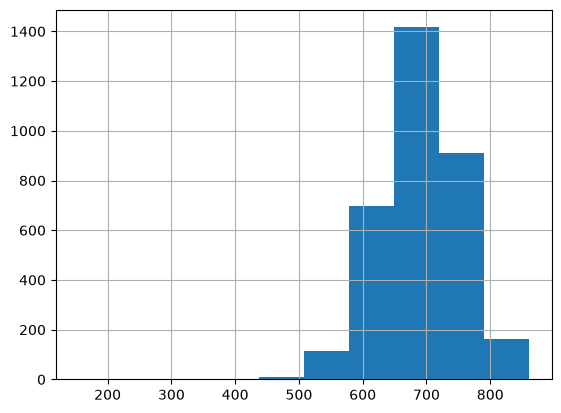

In [36]:
step_questions = [sum(len(g) for g in sample_epoch[s : s + 12]) for s in range(0, len(sample_epoch), 12)]
pd.Series(step_questions, name="questions_per_step").hist()

## 3. Train one epoch

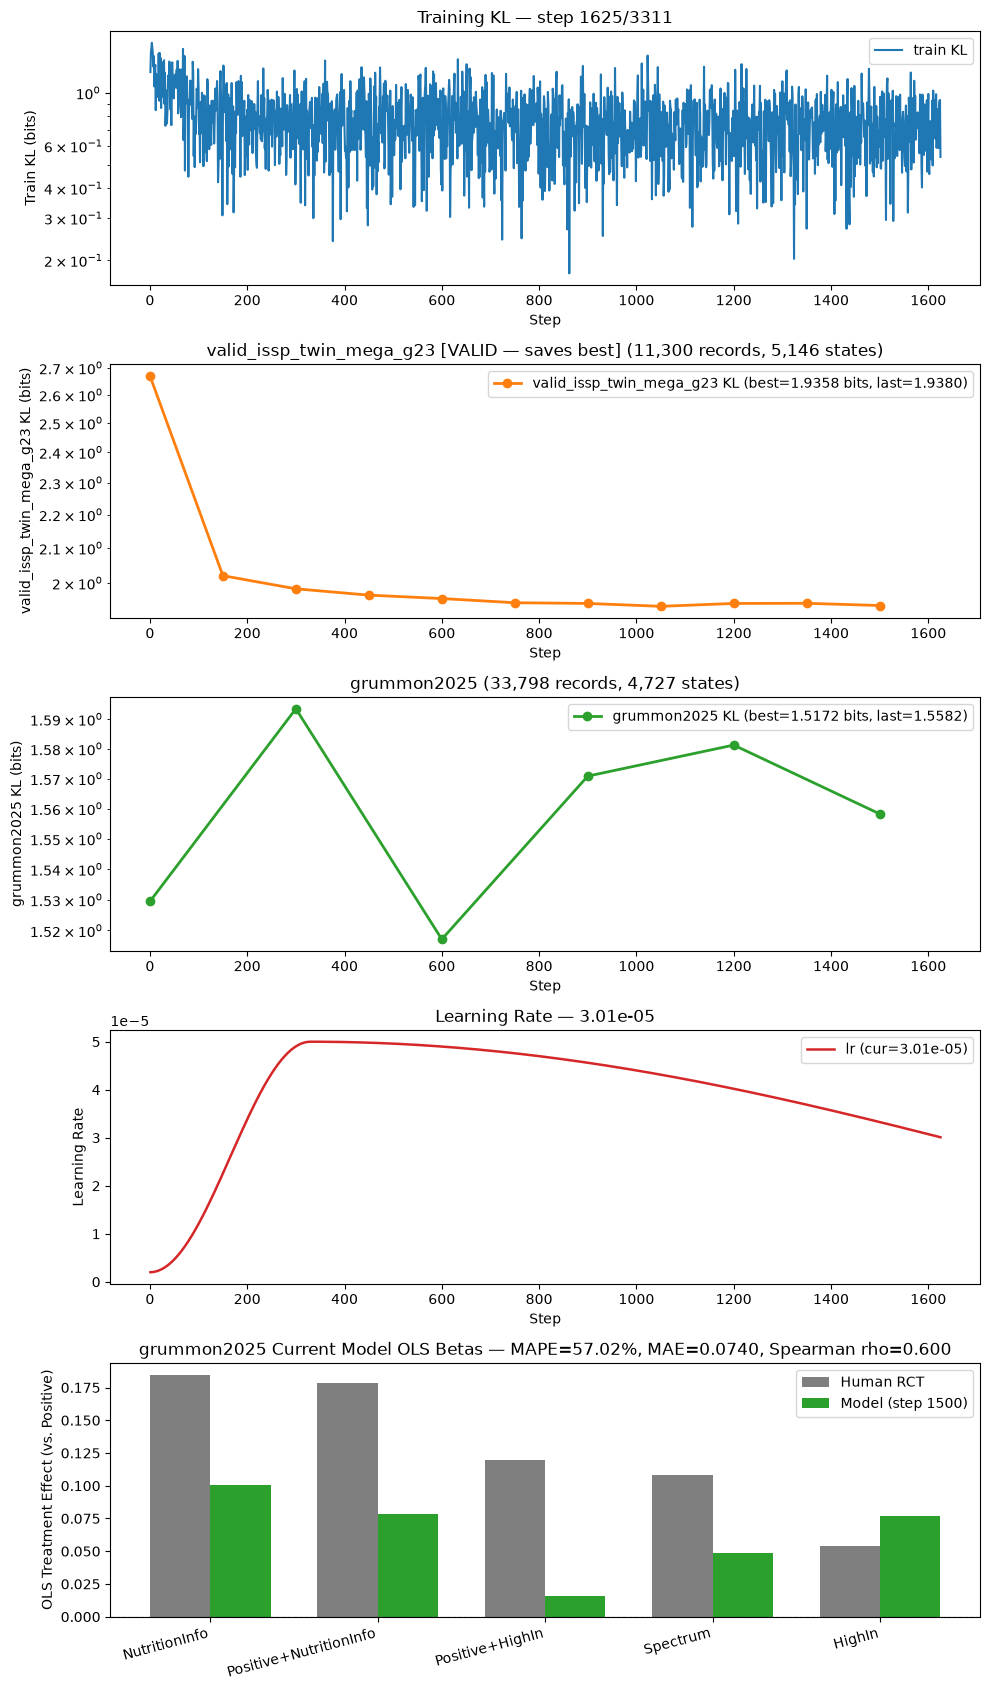

,epoch,step,train_kl,valid_issp_twin_mega_g23_kl,grummon2025_kl,grummon2025_OLS MAPE (%),grummon2025_OLS MAE,grummon2025_OLS MSE,grummon2025_Spearman rho
0,0,0,—,2.6697,1.5294,63.87,0.0650,0.0054,0.5000
1,1,150,0.7592,2.0204,—,—,—,—,—
2,1,300,0.5487,1.9837,1.5935,52.37,0.0724,0.0065,0.6000
3,1,450,0.9902,1.9662,—,—,—,—,—
4,1,600,0.7728,1.9569,1.5172,61.50,0.0867,0.0094,0.3000
5,1,750,0.6842,1.9455,—,—,—,—,—
6,1,900,0.7229,1.9436,1.5708,60.75,0.0873,0.0097,0.3000
7,1,1050,0.7633,1.9358,—,—,—,—,—
8,1,1200,0.5439,1.9435,1.5812,46.77,0.0668,0.0060,0.7000
9,1,1350,0.2710,1.9440,—,—,—,—,—


,human,model,abs_diff
NutritionInfo,0.1844,0.1007,0.0838
Positive+NutritionInfo,0.1788,0.0787,0.1002
Positive+HighIn,0.1194,0.0157,0.1038
Spectrum,0.1083,0.0489,0.0594
HighIn,0.0541,0.0768,0.0227


KeyboardInterrupt: 

In [37]:
plotter = trainer.train()